# 🕒 Proyecto Hospital Obrero - Cuaderno 2: Análisis Exploratorio de Horarios y Franjas
**Objetivo de Negocio:** Identificar patrones de afluencia por horarios para optimizar la asignación de turnos médicos.


### 1. Clasificación por Franjas Horarias
Dividimos las 24 horas del día en 4 franjas operativas de 6 horas.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv('dataset_hospital_obredo_triaje.csv')
df_valid = df[df['Nivel de triaje'].isin([1, 2, 3, 4, 5])].copy()

def obtener_franja(hora_str):
    try:
        h = int(str(hora_str).split(':')[0])
        if 0 <= h < 6: return '00:00 - 06:00'
        elif 6 <= h < 12: return '06:00 - 12:00'
        elif 12 <= h < 18: return '12:00 - 18:00'
        elif 18 <= h < 24: return '18:00 - 24:00'
    except:
        pass
    return None

df_valid['Franja horaria'] = df_valid['Hora'].apply(obtener_franja)
df_valid['Franja horaria'].value_counts()


Franja horaria
06:00 - 12:00    6089
12:00 - 18:00    5786
18:00 - 24:00    1833
00:00 - 06:00    1292


### 2. Tabla Cruzada (Contingencia): Franja Horaria vs Nivel de Triaje
Resumen de frecuencias absolutas por nivel de urgencia.


In [1]:
tabla_crosstab = pd.crosstab(df_valid['Franja horaria'], df_valid['Nivel de triaje'])
orden_franjas = ['00:00 - 06:00', '06:00 - 12:00', '12:00 - 18:00', '18:00 - 24:00']
tabla_crosstab = tabla_crosstab.reindex(orden_franjas, fill_value=0)
tabla_crosstab['Total'] = tabla_crosstab.sum(axis=1)
tabla_crosstab


Nivel de triaje    1    2     3     4     5  Total
Franja horaria                                    
00:00 - 06:00     63  137   301   531   260   1292
06:00 - 12:00    278  607  1533  2395  1276   6089
12:00 - 18:00    303  593  1472  2313  1105   5786
18:00 - 24:00    101  196   467   717   352   1833


### 3. Visualización 1: Volumen Total de Atenciones por Franja


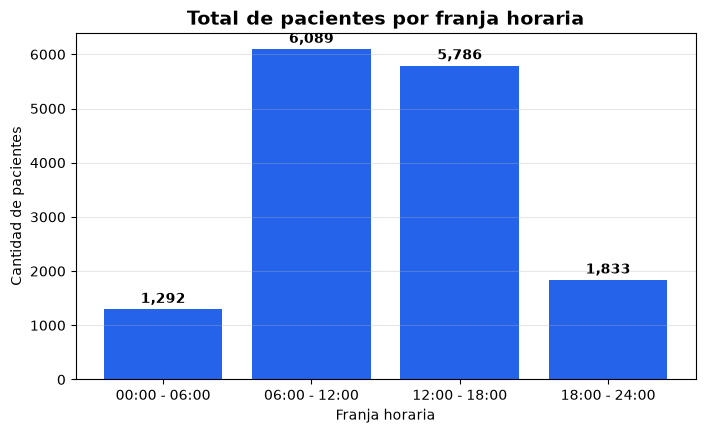

In [1]:
fig, ax = plt.subplots(figsize=(8, 4.5))
x = list(tabla_crosstab.index)
y = tabla_crosstab['Total'].tolist()
ax.bar(x, y, color='#2563EB')
ax.set_title('Total de pacientes por franja horaria', fontsize=14, fontweight='bold')
ax.set_xlabel('Franja horaria')
ax.set_ylabel('Cantidad de pacientes')
ax.grid(axis='y', alpha=0.3)
plt.show()


### 4. Visualización 2: Distribución Porcentual del Triaje por Franja


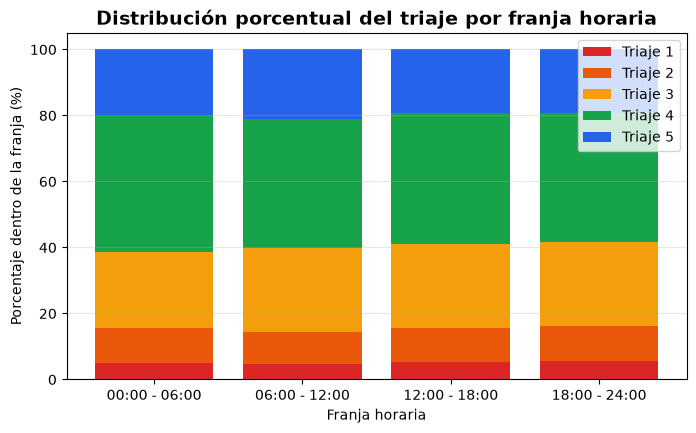

In [1]:
tabla_pct = tabla_crosstab[[1, 2, 3, 4, 5]].div(tabla_crosstab['Total'], axis=0) * 100
fig, ax = plt.subplots(figsize=(8, 4.5))
base = np.zeros(len(x))
colors = ['#DC2626', '#EA580C', '#F59E0B', '#16A34A', '#2563EB']
for idx, lvl in enumerate([1, 2, 3, 4, 5]):
    vals = tabla_pct[lvl].tolist()
    ax.bar(x, vals, bottom=base, label=f'Triaje {lvl}', color=colors[idx])
    base += vals
ax.set_title('Distribución porcentual del triaje por franja horaria', fontsize=14, fontweight='bold')
ax.set_xlabel('Franja horaria')
ax.set_ylabel('Porcentaje dentro de la franja (%)')
ax.legend(loc='upper right')
ax.grid(axis='y', alpha=0.3)
plt.show()
